In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import duckdb
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import ParameterGrid
from sklearn.inspection import PartialDependenceDisplay
from xgboost import XGBClassifier
import shap

In [2]:
df = pd.read_csv('check_fraud.csv')
df = df.set_index('TXN_UID')
df.dtypes

BAD             int64
WGT           float64
FEATURE_2       int64
FEATURE_4       int64
FEATURE_5       int64
               ...   
FEATURE_1      object
FEATURE_67     object
FEATURE_65     object
FEATURE_66     object
FEATURE_48     object
Length: 114, dtype: object

In [6]:
duckdb.sql("""select sum(case when PARTITION = 0 then BAD else 0 end) as BAD_COUNT_TRAIN
                ,sum(case when PARTITION = 0 then BAD else 0 end)/sum(case when PARTITION = 0 then WGT else 0 end) as BAD_RATE_TRAIN
                ,sum(case when PARTITION = 1 then BAD else 0 end) as BAD_COUNT_VALIDATE
                ,sum(case when PARTITION = 1 then BAD else 0 end)/sum(case when PARTITION = 1 then WGT else 0 end) as BAD_RATE_VALIDATE
                ,sum(case when PARTITION = 2 then BAD else 0 end) as BAD_COUNT_TEST
                ,sum(case when PARTITION = 2 then BAD else 0 end)/sum(case when PARTITION = 2 then WGT else 0 end) as BAD_RATE_TEST
                from df
            """)

┌─────────────────┬───────────────────────┬────────────────────┬───────────────────────┬────────────────┬──────────────────────┐
│ BAD_COUNT_TRAIN │    BAD_RATE_TRAIN     │ BAD_COUNT_VALIDATE │   BAD_RATE_VALIDATE   │ BAD_COUNT_TEST │    BAD_RATE_TEST     │
│     int128      │        double         │       int128       │        double         │     int128     │        double        │
├─────────────────┼───────────────────────┼────────────────────┼───────────────────────┼────────────────┼──────────────────────┤
│            1338 │ 0.0020742224954353994 │                590 │ 0.0021154564919840715 │            569 │ 0.002025865816820701 │
└─────────────────┴───────────────────────┴────────────────────┴───────────────────────┴────────────────┴──────────────────────┘

This is unbalance data with plenty of BAD, our target variable

In [7]:
#this function allows me ot look at stability of my features across data partitions

def plot_feature_perf(df: pd.DataFrame, col: str, bins: int):
    
    data = df.copy()
    data['BIN'] = pd.qcut(df[col], q=bins, duplicates='drop')
    data['BIN'] = data['BIN'].astype('string')     
    
    perf_df = duckdb.sql("""select BIN
                            ,sum(case when PARTITION = 0 then BAD else 0 end)/sum(case when PARTITION = 0 then WGT else 0 end) as BAD_RATE_TRAIN
                            ,sum(case when PARTITION = 1 then BAD else 0 end)/sum(case when PARTITION = 1 then WGT else 0 end) as BAD_RATE_VALIDATE
                            ,sum(case when PARTITION = 2 then BAD else 0 end)/sum(case when PARTITION = 2 then WGT else 0 end) as BAD_RATE_TEST
                            from data
                            group by BIN
                            order by BIN
                        """).df()         
   
    fig, ax = plt.subplots(figsize=(16, 5))
    
    ax.plot(perf_df['BIN'], perf_df['BAD_RATE_TRAIN'], color = 'red', label='TRAIN', linestyle='-', marker='o')
    ax.plot(perf_df['BIN'], perf_df['BAD_RATE_VALIDATE'], color = 'orange', label='VALIDATE', linestyle='-', marker='o')
    ax.plot(perf_df['BIN'], perf_df['BAD_RATE_TEST'], color = 'purple', label='TEST', linestyle='-', marker='o')
        
    ax.set_title('BAD CHECK RATES ACROSS PARTITIONS')
    ax.set_xlabel(col)
    ax.set_ylabel('BAD RATE')
    plt.show()            

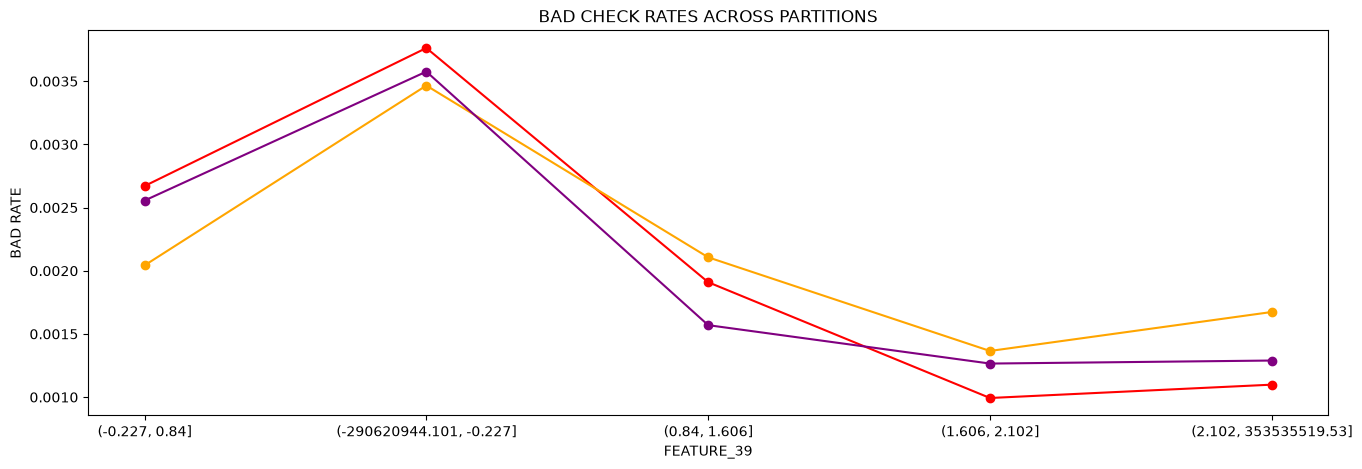

In [8]:
test = plot_feature_perf(df,"FEATURE_39",5)

In [9]:
#need to convert categorical features to binaries, avoid dummy variable trap with drop_first=True
#also note that original categoricals are automatically dropped
cat_cols = df.select_dtypes(include=['object', 'string', 'category']).columns.tolist()
df_encoded = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=int)

In [10]:
#split up the data frame for model training
y_Train = df_encoded.loc[df_encoded['PARTITION'] == 0, ['BAD']].copy().to_numpy().ravel()
X_Train = df_encoded.loc[df_encoded['PARTITION'] == 0].drop(columns=['BAD', 'PARTITION', 'WGT'])
w_Train = df_encoded.loc[df_encoded['PARTITION'] == 0, ['WGT']].copy().to_numpy().ravel()

y_Vdt = df_encoded.loc[df_encoded['PARTITION'] == 1, ['BAD']].copy().to_numpy().ravel()
X_Vdt = df_encoded.loc[df_encoded['PARTITION'] == 1].drop(columns=['BAD', 'PARTITION', 'WGT'])
w_Vdt = df_encoded.loc[df_encoded['PARTITION'] == 1, ['WGT']].copy().to_numpy().ravel()

y_Test = df_encoded.loc[df_encoded['PARTITION'] == 2, ['BAD']].copy().to_numpy().ravel()
X_Test = df_encoded.loc[df_encoded['PARTITION'] == 2].drop(columns=['BAD', 'PARTITION', 'WGT'])
w_Test = df_encoded.loc[df_encoded['PARTITION'] == 2, ['WGT']].copy().to_numpy().ravel()

In [11]:
#define parameter grid
param_grid = {
    'n_estimators': [100, 150, 200],
    'max_depth': [10, 20, 30],
    'min_samples_leaf': [30, 35, 40],
    'max_features': ['sqrt', None],
}

In [12]:
#grid search
best_score = -np.inf
best_params = None
best_model = None
results = []

for params in ParameterGrid(param_grid):
  # Initialize model with current parameter combination
  rf = RandomForestClassifier(**params, random_state=216, n_jobs=-1)

  # Fit on TRAIN using observation weights
  rf.fit(X_Train, y_Train, sample_weight=w_Train)

  # Predict probabilities on VALIDATION
  val_preds = rf.predict_proba(X_Vdt)[:, 1]

  # Score on VALIDATION using observation weights (e.g., Weighted ROC AUC)
  score = roc_auc_score(y_Vdt, val_preds, sample_weight=w_Vdt)

  results.append({**params, 'val_auc': score})

  # Track the best model
  if score > best_score:
    best_score = score
    best_params = params
    best_model = rf

# View all grid results sorted by validation score
results_df = pd.DataFrame(results).sort_values(by='val_auc', ascending=False)
print('Top 5 Grid Search Results:')
print(results_df.head(), '\n')

print(f'Best Validation AUC: {best_score:.4f}')
print(f'Best Parameters: {best_params}\n')

Top 5 Grid Search Results:
    max_depth max_features  min_samples_leaf  n_estimators   val_auc
2          10         sqrt                30           200  0.769611
8          10         sqrt                40           200  0.767678
5          10         sqrt                35           200  0.766285
1          10         sqrt                30           150  0.765866
20         20         sqrt                30           200  0.765729 

Best Validation AUC: 0.7696
Best Parameters: {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 30, 'n_estimators': 200}



In [13]:
#evaluate the best model on the test partition
test_preds = best_model.predict_proba(X_Test)[:, 1]
test_auc = roc_auc_score(y_Test, test_preds, sample_weight=w_Test)
print(f'Final Test Weighted AUC: {test_auc:.4f}')

Final Test Weighted AUC: 0.7814


In [14]:
# Extract and sort feature importances into a DataFrame
importance_df = pd.DataFrame(
    {'feature': best_model.feature_names_in_, 'importance': best_model.feature_importances_}
).sort_values(by='importance', ascending=False)

print(importance_df)

            feature  importance
0         FEATURE_2    0.024020
63       FEATURE_70    0.023832
13       FEATURE_16    0.021341
80       FEATURE_87    0.020765
15       FEATURE_18    0.019360
..              ...         ...
6         FEATURE_9    0.000185
111  FEATURE_66_MID    0.000155
19       FEATURE_22    0.000154
7        FEATURE_10    0.000125
3         FEATURE_6    0.000032

[114 rows x 2 columns]


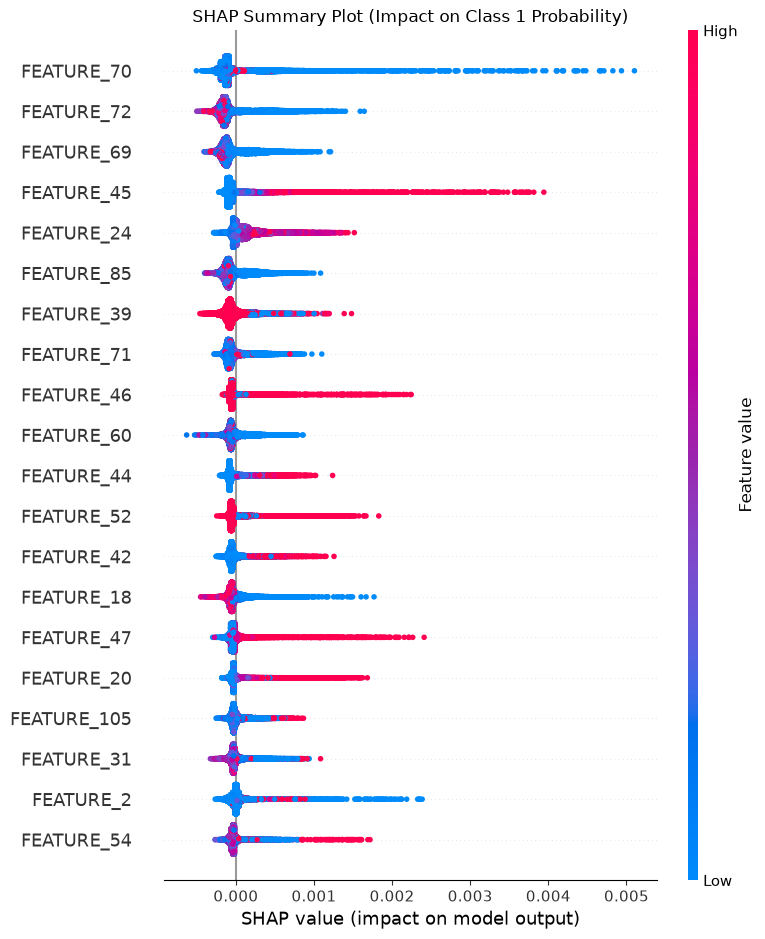

In [15]:
#now look at SHAP Beeswarm plot
explainer = shap.TreeExplainer(best_model)

X_eval = X_Test[best_model.feature_names_in_]
shap_values = explainer.shap_values(X_eval)

#Extract the SHAP values for the positive class (Class 1 / BAD = 1)
if isinstance(shap_values, list):
  shap_values_class1 = shap_values[1]
elif shap_values.ndim == 3:
  shap_values_class1 = shap_values[:, :, 1]
else:
  shap_values_class1 = shap_values  # Fallback for regression models

plt.figure()
shap.summary_plot(shap_values_class1, X_eval, show=False)
plt.title('SHAP Summary Plot (Impact on Class 1 Probability)')
plt.tight_layout()
plt.show()

From above FEATURE_72 shows high global importance, this is showing
High values (RED) show decreased probability/log odd of BAD = 1 (ie low probability of check fraud), this makese business sense
Low values (BLUE) show increased probability/log odd of BAD = 1, also making business sense

In [16]:
#Now I'd like to generate partial dependence plots
def plot_test_pdp(
    model,
    test_df,
    feature,
    sample_weight=None,
    kind='average',
    grid_resolution=50,
    subsample=200,
):

  if sample_weight is not None and len(sample_weight) != len(test_df):
    raise ValueError(
        f'Length of sample_weight ({len(sample_weight)}) does not match'
        f' test_df ({len(test_df)}).'
    )
    
  X_test_eval = test_df[model.feature_names_in_]

  # Create the plot
  fig, ax = plt.subplots(figsize=(7, 4.5))

  PartialDependenceDisplay.from_estimator(
      estimator=model,
      X=X_test_eval,
      features=[feature],
      sample_weight=sample_weight,
      kind=kind,
      grid_resolution=grid_resolution,
      subsample=subsample if kind == 'both' else 1000,
      random_state=42,
      n_jobs=-1,
      ax=ax,
  )

  weight_label = 'Weighted ' if sample_weight is not None else ''
  ax.set_title(f'{weight_label}Partial Dependence: {feature} (Test Data)')
  ax.grid(True, linestyle='--', alpha=0.5)
  plt.tight_layout()
  plt.show()

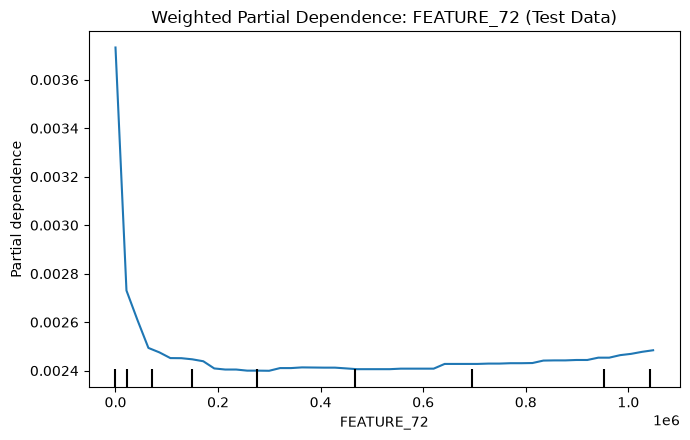

In [17]:
plot_test_pdp(best_model, X_Test, feature='FEATURE_72', sample_weight=w_Test) #PDP for single feature
#plot_test_pdp(best_model, X_Test, feature='FEATURE_72', sample_weight=w_Test, kind='both') #ICE curves across test rows

Cosistent with the SHAP Beeswarm plot show lowest probability of BAD = 1 for higher values

Now gradient boosted models

In [18]:
#hyperparameter grid
param_grid = {
    'max_depth': [20, 30],
    'learning_rate': [0.001, 0.005, 0.01],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0],
    'min_child_weight': [30, 35, 40],
}

In [24]:
best_score = -np.inf
best_params = None
best_model = None
results = []

for params in ParameterGrid(param_grid):
  # Set a high n_estimators and let early_stopping_rounds find the optimal number of trees, would never expect to hit 1,000
  xgb = XGBClassifier(
      **params,
      n_estimators=1000,
      eval_metric='auc',
      early_stopping_rounds=30,
      random_state=216,
      n_jobs=-1,
  )

  # monitor weighted VALIDATION performance
  xgb.fit(
      X_Train,
      y_Train,
      sample_weight=w_Train,
      eval_set=[(X_Vdt, y_Vdt)],
      sample_weight_eval_set=[w_Vdt],
      verbose=False,
  )

  # Predict probabilities on VALIDATION (automatically uses best_iteration)
  val_preds = xgb.predict_proba(X_Vdt)[:, 1]
  score = roc_auc_score(y_Vdt, val_preds, sample_weight=w_Vdt)

  results.append({
      **params,
      'best_iteration': xgb.best_iteration,
      'val_auc': score,
  })

  if score > best_score:
    best_score = score
    best_params = {**params, 'n_estimators': xgb.best_iteration}
    best_model = xgb

# View top 5 parameter combinations on validation data
results_df = pd.DataFrame(results).sort_values(by='val_auc', ascending=False)
print('Top 5 Grid Search Results:')
print(results_df.head(), '\n')

print(f'Best Validation Weighted AUC: {best_score:.4f}')
print(f'Best Parameters: {best_params}\n')

#Final Evaluation on Test DataFrame
test_preds = best_model.predict_proba(X_Test)[:, 1]
test_auc = roc_auc_score(y_Test, test_preds, sample_weight=w_Test)
print(f'Final Test Weighted AUC: {test_auc:.4f}')

Top 5 Grid Search Results:
    colsample_bytree  learning_rate  max_depth  min_child_weight  subsample  \
67               1.0          0.010         30                30        1.0   
61               1.0          0.010         20                30        1.0   
31               0.8          0.010         30                30        1.0   
13               0.8          0.005         20                30        1.0   
19               0.8          0.005         30                30        1.0   

    best_iteration   val_auc  
67             389  0.785330  
61             389  0.785330  
31             388  0.784657  
13             663  0.784653  
19             663  0.784653   

Best Validation Weighted AUC: 0.7853
Best Parameters: {'colsample_bytree': 1.0, 'learning_rate': 0.01, 'max_depth': 20, 'min_child_weight': 30, 'subsample': 1.0, 'n_estimators': 389}

Final Test Weighted AUC: 0.7829


We see an increase in AUC slightly over random forest AND it looks relatively stable from Validation data to Test

In [25]:
# Extract and sort feature importances into a DataFrame
importance_df = pd.DataFrame(
    {'feature': best_model.feature_names_in_, 'importance': best_model.feature_importances_}
).sort_values(by='importance', ascending=False)

print(importance_df)

             feature  importance
62        FEATURE_69    0.174992
78        FEATURE_85    0.031507
63        FEATURE_70    0.027207
65        FEATURE_72    0.025520
42        FEATURE_45    0.023476
..               ...         ...
106  FEATURE_106_MID    0.000000
109   FEATURE_67_LOW    0.000000
110   FEATURE_66_LOW    0.000000
111   FEATURE_66_MID    0.000000
112   FEATURE_48_LOW    0.000000

[114 rows x 2 columns]


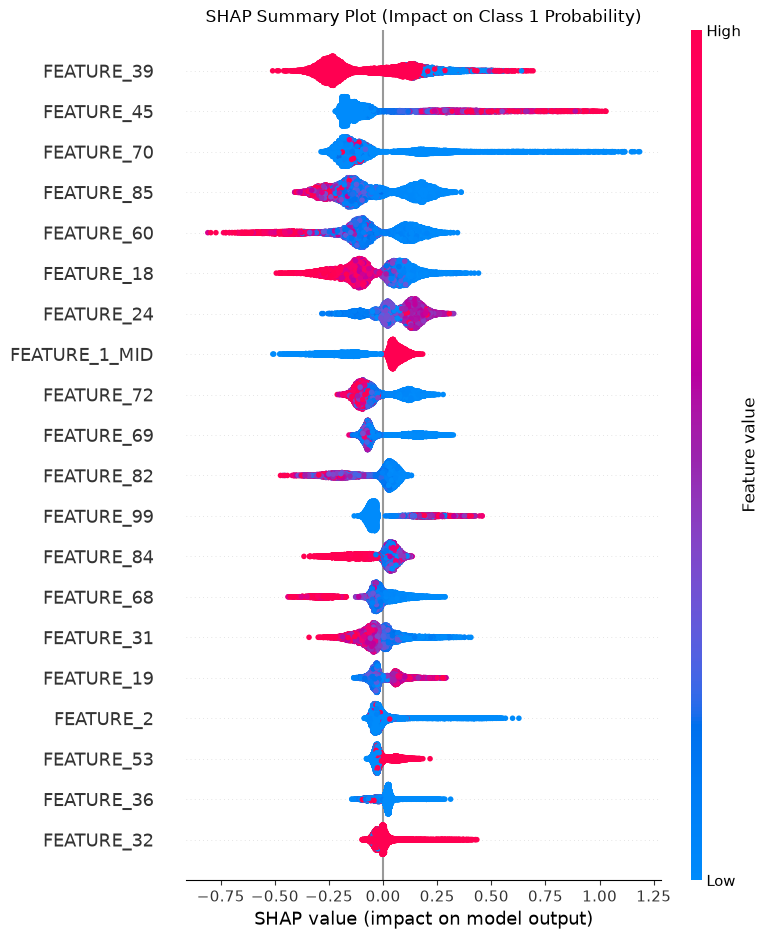

In [26]:
#now look at SHAP Beeswarm plot
explainer = shap.TreeExplainer(best_model)

X_eval = X_Test[best_model.feature_names_in_]
shap_values = explainer.shap_values(X_eval)

#Extract the SHAP values for the positive class (Class 1 / BAD = 1)
if isinstance(shap_values, list):
  shap_values_class1 = shap_values[1]
elif shap_values.ndim == 3:
  shap_values_class1 = shap_values[:, :, 1]
else:
  shap_values_class1 = shap_values  # Fallback for regression models

plt.figure()
shap.summary_plot(shap_values_class1, X_eval, show=False)
plt.title('SHAP Summary Plot (Impact on Class 1 Probability)')
plt.tight_layout()
plt.show()

This is a shift from what we saw with random forest.
FEATURE_39 is interesting, for this one we see large values (RED) show lower probability of bad
Also some large value pockets showing high probability of bad and low values (BLUE) generally higher probability of bad

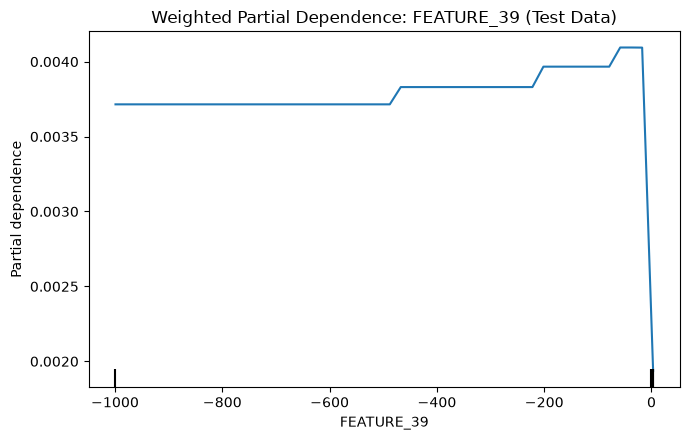

In [27]:
#using my parital dependence plot function can see the shape of this below, 
#-999 represents null values and smaller negative values are higher risk
plot_test_pdp(best_model, X_Test, feature='FEATURE_39', sample_weight=w_Test) #PDP for single feature

One class of high risk value is -999 which represents null value. Highest risk is lower absolute value of negative as epected. Low positive values low risk as expected.

In [28]:
#with gradient boosted models I have had cases where the prediced bad rates were no where near actual
#this is due in part to the overfit nature of the models, this function will look at this
def plot_weighted_lift_chart(model, X_test, y_test, sample_weight=None, n_bins=10):

  # Align columns and generate predicted probabilities for Class 1 (BAD = 1)
  X_eval = X_test[model.feature_names_in_]
  preds = model.predict_proba(X_eval)[:, 1]

    # Default to equal weights of 1.0 if none are provided
  weights = (
      np.ones(len(y_test))
      if sample_weight is None
      else np.asarray(sample_weight)
  )

  # Build evaluation DataFrame and sort highest risk -> lowest risk
  df = pd.DataFrame({
      'actual': np.asarray(y_test),
      'pred': preds,
      'weight': weights,
  }).sort_values(by='pred', ascending=False)

  # Assign into equal-weight bins (Decile 1 = highest predicted risk)
  cum_weight = df['weight'].cumsum()
  total_weight = df['weight'].sum()
  df['decile'] = np.ceil((cum_weight / total_weight) * n_bins).astype(int)
  df['decile'] = df['decile'].clip(1, n_bins)  # Handle floating-point edge cases

  # 4. Compute weighted actual and weighted predicted bad rates per decile
  df['weighted_actual'] = df['actual'] * df['weight']
  df['weighted_pred'] = df['pred'] * df['weight']

  summary = (
      df.groupby('decile')
      .agg(
          total_w=('weight', 'sum'),
          sum_actual=('weighted_actual', 'sum'),
          sum_pred=('weighted_pred', 'sum'),
      )
      .reset_index()
  )

  summary['actual_bad_rate'] = summary['sum_actual'] / summary['total_w']
  summary['pred_bad_rate'] = summary['sum_pred'] / summary['total_w']
  overall_bad_rate = df['weighted_actual'].sum() / total_weight
  summary['lift'] = summary['actual_bad_rate'] / overall_bad_rate

  # Plot Predicted vs. Actual Bad Rate by Decile
  fig, ax = plt.subplots(figsize=(9, 5))

  ax.plot(
      summary['decile'],
      summary['actual_bad_rate'],
      marker='o',
      linewidth=2.5,
      color='red',
      label='Actual Bad Rate',
  )
  ax.plot(
      summary['decile'],
      summary['pred_bad_rate'],
      marker='o',
      linestyle='--',
      linewidth=2.5,
      color='purple',
      label='Predicted Bad Rate',
  )
  ax.axhline(
      overall_bad_rate,
      color='gray',
      linestyle=':',
      linewidth=2.5,
      label=f'Overall Avg Bad Rate ({overall_bad_rate:.1%})',
  )

  ax.set_xticks(range(1, n_bins + 1))
  ax.set_xlabel(f'Risk Decile (1 = Highest Predicted Risk, {n_bins} = Lowest)')
  ax.set_ylabel('Weighted Bad Rate')
  ax.set_title('Test Set Lift Chart: Predicted vs. Actual Bad Rate by Decile')
  ax.yaxis.set_major_formatter(
      plt.FuncFormatter(lambda y, _: f'{y:.1%}')
  )  # Format as %
  ax.grid(True, linestyle='--', alpha=0.5)
  ax.legend()

  plt.tight_layout()
  plt.show()

  return summary[['decile', 'total_w', 'pred_bad_rate', 'actual_bad_rate', 'lift']]

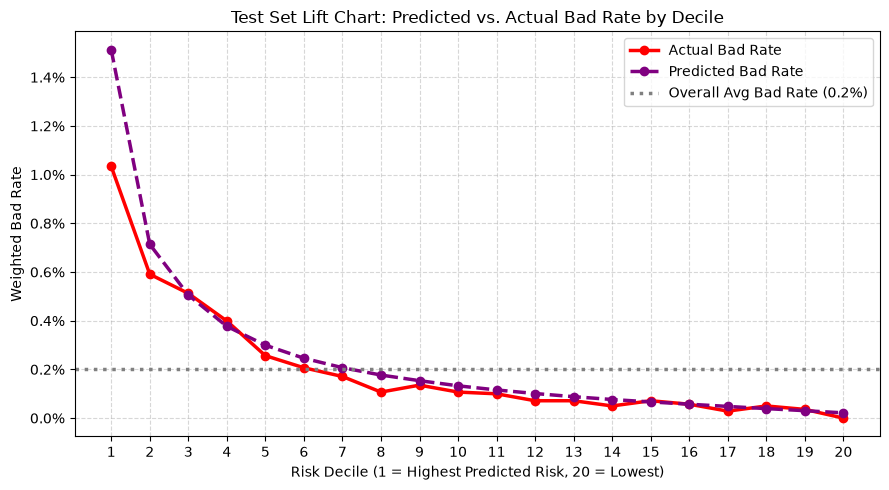

 decile     total_w  pred_bad_rate  actual_bad_rate     lift
      1 14026.64805       0.015130         0.010337 5.102740
      2 14046.66665       0.007137         0.005909 2.916716
      3 14056.17130       0.005055         0.005122 2.528452
      4 14040.17130       0.003769         0.003989 1.968815
      5 14040.67595       0.002994         0.002564 1.265621
      6 14033.67595       0.002459         0.002066 1.020037
      7 14049.18060       0.002070         0.001708 0.843237
      8 14040.18060       0.001768         0.001068 0.527361
      9 14044.18060       0.001536         0.001353 0.667800
     10 14040.18060       0.001326         0.001068 0.527361
     11 14039.18060       0.001156         0.000997 0.492239
     12 14055.68525       0.001009         0.000711 0.351186
     13 14035.18060       0.000879         0.000712 0.351699
     14 14052.68525       0.000763         0.000498 0.245883
     15 14035.18060       0.000663         0.000712 0.351699
     16 14053.68525     

In [29]:
lift_table = plot_weighted_lift_chart(best_model, X_Test, y_Test, sample_weight=w_Test, n_bins=20)
print(lift_table.to_string(index=False))